# Bonus B3: How to build the desk agent with Google ADK and LiteLLM

## Goal

We build the Chinook desk agent with Google ADK while OpenAI remains the model provider. The moment comes when we read a model's function request beside the Python result, then find the user's message in the stored session: **an event count is not a model-call count**. A deliberately wrong session ID then shows why continuing a conversation needs the right runtime state.

## What you will learn

- How to call LiteLLM directly and read its reply and usage fields.
- How to construct ADK's `LiteLlm` adapter before giving it to an agent.
- How to give an ADK agent three read-only tools and run it with a session service.
- How to read raw events, session state and a second turn without confusing tool results with model requests.
- How to measure requests, tokens, time and estimated cost, and check the facts against the database.
- When ADK and LiteLLM are worth their extra layers, compared with lab 07's Agents SDK.

## Setup

This lab has its own environment: follow this folder's [README](../README.md) to create it and select its Python interpreter. The notebook needs only an OpenAI key at the repository root; no Google account or Google key is used. Run top to bottom; every object is defined here.

The config cell finds the repository root, model settings and your key without printing the key; Lab 00 explains it line by line.


In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")


model: gpt-6-luna | reasoning effort: none | key found: yes


We disable LiteLLM's optional usage telemetry and OpenTelemetry exporting, and use LiteLLM's packaged model-cost map. The price calculation later uses our settings instead of that map. These settings affect reporting, not the agent's tools or answers.


In [2]:
import json
import sqlite3
from time import perf_counter
from importlib.metadata import version

# Set these before importing the libraries: use the packaged price map and no telemetry exporters.
os.environ["LITELLM_LOCAL_MODEL_COST_MAP"] = "true"
os.environ["OTEL_SDK_DISABLED"] = "true"
import litellm
litellm.telemetry = False

print({name: version(name) for name in ["google-adk", "litellm", "openai", "mcp"]})


{'google-adk': '2.13.0', 'litellm': '1.106.6', 'openai': '2.54.0', 'mcp': '2.3.0'}


## The adapter and the runtime

Read the arrows as requests and results. The ink node is the model that chooses the next call; the lime nodes run our application. `Runner` loads and saves the conversation through the session service. The `LiteLlm` connector translates ADK objects into LiteLLM calls, and LiteLLM routes them to OpenAI.

LiteLLM's in-process Python SDK is used here. Its separately deployed Proxy is another product surface; this notebook starts no gateway or web server.


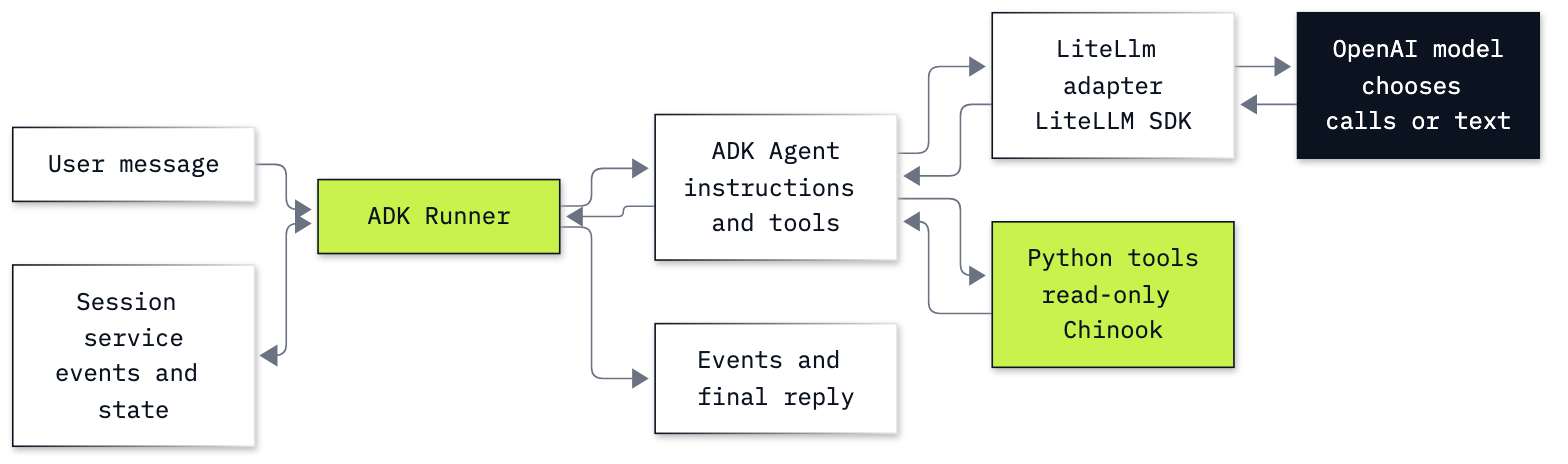

In [3]:
from IPython.display import Image

LAB = ROOT / "bonus" / "B3_Google_ADK"
Image(filename=str(LAB / "resources" / "labB3_adapter_and_runtime.png"), width=760)


## Part A: Read a model call through LiteLLM

Start with one small question so we can read a complete result before an agent adds tools and history. In `openai/<model>`, `openai/` selects the provider adapter. OpenAI still performs the inference.

`messages` is a list with one user-message dictionary. `max_completion_tokens` caps generated tokens; effort comes from the settings. The dictionary unpacking `**...` includes `reasoning_effort` only when an effort is configured. A common interface does not make every provider support the same parameters.


In [4]:
ROUTED_MODEL = f"openai/{MODEL}"
model_options = {"reasoning_effort": EFFORT} if EFFORT else {}
small_messages = [{"role": "user", "content": "What is 2 + 3? Answer with the number only."}]
print(small_messages)


[{'role': 'user', 'content': 'What is 2 + 3? Answer with the number only.'}]


Now call the [LiteLLM completion API](https://docs.litellm.ai/docs/completion/input). The input is readable before it reaches the library; inspect the message and token fields in the returned envelope.


In [5]:
from litellm import completion

started = perf_counter()
direct = completion(model=ROUTED_MODEL, messages=small_messages,
                    max_completion_tokens=80, **model_options)
direct_seconds = perf_counter() - started
print(type(direct).__name__)
print(direct.choices[0].message.model_dump(exclude_none=True))
print("finish reason:", direct.choices[0].finish_reason)
print("usage:", direct.usage.model_dump(exclude_none=True))


ModelResponse
{'content': '5', 'role': 'assistant', 'provider_specific_fields': {'refusal': None}, 'annotations': []}
finish reason: stop
usage: {'completion_tokens': 4, 'prompt_tokens': 20, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'cache_creation_tokens': 0}}


`ModelResponse` is the response envelope. `choices[0]` is its first completion; `.message.content` contains the answer. The saved reply is `5`. `stop` means the provider finished the reply; a token limit would need a different interpretation.

In [LiteLLM's output fields](https://docs.litellm.ai/docs/completion/output), `prompt_tokens` measures the input sent to the provider, `completion_tokens` the generated output, and `total_tokens` their sum. They include message-format overhead, so the input count is larger than the words in our question.

**Checkpoint A:** explain which part of the routed name chooses the adapter and which service answered.


## Part B: Use ADK's model adapter directly

ADK does not consume a LiteLLM `ModelResponse` directly. Its [`LiteLlm` connector](https://adk.dev/agents/models/litellm/) translates between ADK's `LlmRequest` / `LlmResponse` objects and LiteLLM. Construct that public object first, before an agent owns it.


In [6]:
from google.adk.models.lite_llm import LiteLlm
from google.adk.models.llm_request import LlmRequest
from google.genai import types

adapter = LiteLlm(model=ROUTED_MODEL, **model_options)
small_content = types.Content(role="user", parts=[types.Part.from_text(text=small_messages[0]["content"])])
print("adapter:", type(adapter).__name__)
print("content:", small_content.model_dump(exclude_none=True))


adapter: LiteLlm
content: {'parts': [{'text': 'What is 2 + 3? Answer with the number only.'}], 'role': 'user'}


`Content` groups one speaker's message; `parts` is a list because a message may hold text or structured tool payloads. ADK uses `max_output_tokens` in `GenerateContentConfig`. The connector translates the generation settings for the provider.

`generate_content_async` is an asynchronous iterator: `async for` waits for each response without blocking other tasks. A notebook already has an event loop, so we use top-level `await` and `async for` directly; do not wrap them in `asyncio.run`. Here `stream=False` asks for complete responses.


In [7]:
small_request = LlmRequest(contents=[small_content],
                           config=types.GenerateContentConfig(max_output_tokens=80))
print("request content:", small_request.contents[0].model_dump(exclude_none=True))
small_replies = []
async for reply in adapter.generate_content_async(small_request, stream=False):
    small_replies.append(reply)
    print(type(reply).__name__)
    print(reply.model_dump(exclude_none=True))


request content: {'parts': [{'text': 'What is 2 + 3? Answer with the number only.'}], 'role': 'user'}


LlmResponse
{'model_version': 'gpt-6-luna', 'content': {'parts': [{'text': '5'}], 'role': 'model'}, 'partial': False, 'finish_reason': <FinishReason.STOP: 'STOP'>, 'usage_metadata': {'cached_content_token_count': 0, 'candidates_token_count': 4, 'prompt_token_count': 20, 'total_token_count': 24}}


The answer remains `5`. The wrapper returns an `LlmResponse` with role `model`, text inside `content.parts`, and `usage_metadata` with ADK's names. No agent loop or session was needed for either small call.

**Checkpoint B:** find the same three quantities under the new names: `prompt_token_count`, `candidates_token_count` and `total_token_count`. The adapter owns translation; the next part gives an agent its instructions and tools.


## Part C: Give the desk agent three read-only tools

Our task needs three facts: Helena Holý's invoice count, their total, and her support rep. We first read the source row, then define narrow tools over that database. The database is the historical Chinook sample music shop; these are fixture records, not live business records.

`mode=ro` opens the file read-only. `uri=True` makes SQLite interpret that option, and `check_same_thread=False` permits ADK's tool execution to use the connection from another thread. It does not grant write access.


In [8]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)
row = conn.execute("SELECT CustomerId, FirstName, LastName, Country FROM customers WHERE CustomerId = 6").fetchone()
print(dict(zip(["customer_id", "first_name", "last_name", "country"], row)))


{'customer_id': 6, 'first_name': 'Helena', 'last_name': 'Holý', 'country': 'Czech Republic'}


`fetchone()` returned a tuple in the `SELECT` column order. `zip` paired each label with the value in the same position, and `dict` gave those pairs readable field names. The row gives customer ID 6. Each tool below has one responsibility: `find_customer` returns a list of matches, `get_invoices` returns one count and total, and `get_support_rep` returns one rep name. We use the same three functions as Lab 07, defined inline so this lab stands alone.

`?` placeholders bind values as SQL parameters. The model supplies the name or ID, never SQL text. Type annotations and docstrings describe the arguments to ADK; the return dictionaries carry the facts back. An exact-name lookup may return `[]` when the spelling differs.


In [9]:
def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}


Call the functions as ordinary Python before asking a model to use them. Only the question will be sent as the user message later; these checks are our local answer key.


In [10]:
customer = find_customer("Helena Holý")[0]
print(customer)
print(get_invoices(customer["customer_id"]))
print(get_support_rep(customer["customer_id"]))


{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


The source gives **7 invoices, $49.62 and Steve Johnson**. These values let us check the later reply; fluent wording alone is not evidence that the database was read.

Now construct an [`LlmAgent`](https://adk.dev/agents/llm-agents/). `instruction` is the short desk instruction, `model` is the adapter we already ran, and `tools` is our three-function list. `output_key="last_answer"` asks ADK to put final text into session state; it does not validate that text.


In [11]:
from google.adk.agents import LlmAgent

SYSTEM = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. "
          "Answer in one or two sentences.")
desk = LlmAgent(name="Desk", model=adapter, instruction=SYSTEM,
                tools=[find_customer, get_invoices, get_support_rep],
                output_key="last_answer",
                generate_content_config=types.GenerateContentConfig(max_output_tokens=200))
print("agent:", desk.name)
print("instruction:", desk.instruction)
print("adapter:", type(desk.model).__name__)
print("tools:", [tool.__name__ for tool in desk.tools])


agent: Desk
instruction: You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. Answer in one or two sentences.
adapter: LiteLlm
tools: ['find_customer', 'get_invoices', 'get_support_rep']


An agent definition does not retain a conversation. [`InMemorySessionService`](https://adk.dev/sessions/session/) stores events and state in this Python process. An application name, user ID and session ID select one conversation. We create that conversation before giving the service to `Runner`.

`await` waits for an asynchronous operation to finish. The returned session starts with empty state and no events; a persistent service would be needed to keep it across a process restart.


In [12]:
from google.adk.sessions import InMemorySessionService

APP_NAME = "chinook_adk"
USER_ID = "learner"
SESSION_ID = "helena"
service = InMemorySessionService()
session = await service.create_session(app_name=APP_NAME, user_id=USER_ID, session_id=SESSION_ID)
print("session:", session.id, "| state:", session.state, "| events:", len(session.events))


session: helena | state: {} | events: 0


`Runner` joins the agent definition and session service. It will load conversation history, ask the model, execute registered tools, and append events. We still own the SQL and the rule that the connection is read-only.


In [13]:
from google.adk.runners import Runner

runner = Runner(agent=desk, app_name=APP_NAME, session_service=service)
QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"
user_message = types.Content(role="user", parts=[types.Part.from_text(text=QUESTION)])
print(user_message.model_dump(exclude_none=True))


{'parts': [{'text': 'How many invoices does Helena Holý have, what do they add up to, and who is her support rep?'}], 'role': 'user'}


Before running, predict the tool order: can invoice and rep lookups happen before the customer ID is known?

We retain each yielded `Event` before reducing anything to text. `async for` waits for the runner's next event; `.append` keeps that object in order. This is the library's loop, not a helper that hides its construction.


In [14]:
events = []
started = perf_counter()
async for event in runner.run_async(user_id=USER_ID, session_id=SESSION_ID, new_message=user_message):
    events.append(event)
elapsed = perf_counter() - started
print("yielded events:", len(events))
print("first event:")
print(events[0].model_dump(exclude_none=True))


yielded events: 5
first event:
{'model_version': 'gpt-6-luna', 'content': {'parts': [{'function_call': {'id': 'call_4uG8BxjkDk9Qpy50rIxwm0IO', 'args': {'name': 'Helena Holý'}, 'name': 'find_customer'}}], 'role': 'model'}, 'partial': False, 'finish_reason': <FinishReason.STOP: 'STOP'>, 'usage_metadata': {'cached_content_token_count': 0, 'candidates_token_count': 20, 'prompt_token_count': 302, 'total_token_count': 322}, 'invocation_id': 'e-88ca15c5-cb4c-450b-905c-e98b448ec282', 'author': 'Desk', 'actions': {'state_delta': {}, 'artifact_delta': {}, 'requested_auth_configs': {}, 'requested_tool_confirmations': {}}, 'node_info': {'path': 'Desk@1'}, 'long_running_tool_ids': [], 'id': 'e79b5841-a814-44c4-9929-c484b2f5de8f', 'timestamp': 1793607836.875883}


The first event contains a `function_call`: its `name` is the requested function, and `args` is a Python dictionary of arguments decoded from the model's response. The `id` ties it to the result. `usage_metadata` belongs to this model request. The model proposed the call; the runner invokes our registered Python function.

**Checkpoint C:** the agent has three tools, and the first request identifies Helena before invoice and rep lookup. We now read the complete sequence rather than guessing from one event.


## Part D: Read events, state and model usage

A final sentence hides the difference between a model request, a tool execution and a stored user message. [ADK events](https://adk.dev/events/) expose those boundaries. First read each raw content object, then create a compact table.

`get_function_calls()` returns every requested call in that event; `get_function_responses()` returns every tool result. One event may contain more than one call or result.


In [15]:
for index, event in enumerate(events, start=1):
    print("event", index, "author:", event.author)
    print("content:", event.content.model_dump(exclude_none=True) if event.content else None)
    print("state delta:", event.actions.state_delta)
    print("usage:", event.usage_metadata.model_dump(exclude_none=True) if event.usage_metadata else None)


event 1 author: Desk
content: {'parts': [{'function_call': {'id': 'call_4uG8BxjkDk9Qpy50rIxwm0IO', 'args': {'name': 'Helena Holý'}, 'name': 'find_customer'}}], 'role': 'model'}
state delta: {}
usage: {'cached_content_token_count': 0, 'candidates_token_count': 20, 'prompt_token_count': 302, 'total_token_count': 322}
event 2 author: Desk
content: {'parts': [{'function_response': {'id': 'call_4uG8BxjkDk9Qpy50rIxwm0IO', 'name': 'find_customer', 'response': {'result': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}}}], 'role': 'user'}
state delta: {}
usage: None
event 3 author: Desk
content: {'parts': [{'function_call': {'id': 'call_HuHZ77aDfU7bjjxQbytu0SbY', 'args': {'customer_id': 6}, 'name': 'get_invoices'}}, {'function_call': {'id': 'call_Ez3ClVS7v2iKOXxn40TsYUiK', 'args': {'customer_id': 6}, 'name': 'get_support_rep'}}], 'role': 'model'}
state delta: {}
usage: {'cached_content_token_count': 0, 'candidates_token_count': 51, 'prompt_token_count': 361, 'total_tok

The saved sequence has 5 yielded events. `find_customer` returns a list, so ADK wraps it under `response["result"]`; the two dictionary-returning tools retain their named fields. Follow their IDs back to the corresponding `function_call` objects.

The invoice and support-rep calls share one model event in this run. Their results share another event, with role `user` even though the `author` is `Desk`: the role means input returned to the model. It is not a second human message. The final model event puts `last_answer` into `actions.state_delta`.

The table below summarizes objects we have already inspected. We use `enumerate(..., start=1)` to attach a readable row number without changing the event order.


In [16]:
for index, event in enumerate(events, start=1):
    print({"event": index, "author": event.author,
           "calls": [call.name for call in event.get_function_calls()],
           "results": [result.name for result in event.get_function_responses()],
           "final": event.is_final_response(), "model_usage": event.usage_metadata is not None})


{'event': 1, 'author': 'Desk', 'calls': ['find_customer'], 'results': [], 'final': False, 'model_usage': True}
{'event': 2, 'author': 'Desk', 'calls': [], 'results': ['find_customer'], 'final': False, 'model_usage': False}
{'event': 3, 'author': 'Desk', 'calls': ['get_invoices', 'get_support_rep'], 'results': [], 'final': False, 'model_usage': True}
{'event': 4, 'author': 'Desk', 'calls': [], 'results': ['get_invoices', 'get_support_rep'], 'final': False, 'model_usage': False}
{'event': 5, 'author': 'Desk', 'calls': [], 'results': [], 'final': True, 'model_usage': True}


Now fetch the stored session again. The runner also stores the user's input, which it does not yield in the returned stream. Compare the first stored event with `user_message` above before interpreting the counts.


In [17]:
saved = await service.get_session(app_name=APP_NAME, user_id=USER_ID, session_id=SESSION_ID)
print("first stored event:", saved.events[0].content.model_dump(exclude_none=True))
print("first stored author:", saved.events[0].author)
print("yielded:", len(events), "| stored:", len(saved.events))
print("state:", saved.state)


first stored event: {'parts': [{'text': 'How many invoices does Helena Holý have, what do they add up to, and who is her support rep?'}], 'role': 'user'}
first stored author: user
yielded: 5 | stored: 6
state: {'last_answer': 'Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.'}


We stored 6 events: the user's input plus the 5 yielded events. The two tool-result events have no model usage because Python produced them. Count usage-bearing model events to measure requests; do not count all events as billable model calls.

[`output_key`](https://adk.dev/sessions/state/) saved final text as `last_answer`. History and state are different: the history records the conversation, while this state key holds a selected value. Next we check the answer against the actual tool results.

The next cell collects tool names with `.extend`, keeps each returned payload under its tool name, and joins the final text parts with `"".join(...)`. The checks compare these values with the source. `all(checks.values())` is true only when every named check passed.


In [18]:
final_text = ""
called_tools = []
returned = {}
for event in events:
    called_tools.extend(call.name for call in event.get_function_calls())
    for result in event.get_function_responses():
        returned[result.name] = result.response
    if event.is_final_response() and event.content:
        final_text = "".join(part.text or "" for part in event.content.parts)
print(final_text)
checks = {
    "all three tools ran": set(called_tools) == {"find_customer", "get_invoices", "get_support_rep"},
    "invoice result": returned["get_invoices"] == get_invoices(6),
    "rep result": returned["get_support_rep"] == get_support_rep(6),
    "answer facts": all(value in final_text for value in ["7", "49.62", "Steve Johnson"]),
    "answer saved": saved.state["last_answer"] == final_text,
}
print(checks)
assert all(checks.values())
print("✅ The run used the tools, returned the database facts and saved its final answer.")


Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.
{'all three tools ran': True, 'invoice result': True, 'rep result': True, 'answer facts': True, 'answer saved': True}
✅ The run used the tools, returned the database facts and saved its final answer.


These checks join two kinds of evidence: the tools returned the database values, and the reply includes the three facts. The substring check is a small fixture check, not a general factual evaluator. We inspected the complete reply above so an extra contradictory statement would remain visible.

### Price the model requests

For each usage-bearing event, read input, cached input and output separately. `prompt_token_count` includes cached tokens. This connector exposes cache reads, but its ADK event does not preserve OpenAI's nested cache-write field. Each Helena request in this run is below the configured model's [1,024-token caching threshold](https://developers.openai.com/api/docs/guides/prompt-caching); the estimate therefore uses zero writes. For longer prompts, retain the provider's complete usage before conversion instead of inferring zero from an absent event field.

Cost is ordinary input × input price + cached input × cached price + output × output price, divided by one million. The settings hold dollars per million tokens. Local SQL tool results add no separate provider charge; their text becomes input in the next model request.


In [19]:
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_CACHED = float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
PRICE_WRITE = float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
usage_rows = []
for event in events:
    usage = event.usage_metadata
    if usage:
        usage_rows.append({"input": usage.prompt_token_count or 0,
                           "cached": usage.cached_content_token_count or 0,
                           "output": usage.candidates_token_count or 0})
print("per request:", usage_rows)
input_tokens = sum(row["input"] for row in usage_rows)
cached_tokens = sum(row["cached"] for row in usage_rows)
output_tokens = sum(row["output"] for row in usage_rows)
agent_cost = ((input_tokens - cached_tokens) * PRICE_IN + cached_tokens * PRICE_CACHED
              + output_tokens * PRICE_OUT) / 1_000_000
print({"requests": len(usage_rows), "input_tokens": input_tokens, "cached_tokens": cached_tokens,
       "output_tokens": output_tokens, "seconds": round(elapsed, 3), "estimated_usd": round(agent_cost, 8)})


per request: [{'input': 302, 'cached': 0, 'output': 20}, {'input': 361, 'cached': 0, 'output': 51}, {'input': 464, 'cached': 0, 'output': 24}]
{'requests': 3, 'input_tokens': 1127, 'cached_tokens': 0, 'output_tokens': 95, 'seconds': 4.238, 'estimated_usd': 0.0001602}


In the saved run, 3 model requests used 1127 input and 95 output tokens, with 0 cached input; elapsed time was 4.238 seconds and estimated cost was $0.0001602. Time includes provider calls and local runtime work, and varies with network and service load.

Notice that the later requests grow: ADK sends the tool results and history along with the question. The framework removes our hand-written dispatch loop, while the model still receives context and generates a reply on each request.

**Checkpoint D:** identify 3 usage-bearing events, 5 yielded events and 6 stored events in this run. Explain why these are different counts. Verify 7 invoices, $49.62 and Steve Johnson against the raw tool results.


## Part E: Continue the right session

The same agent and model are not enough to continue a conversation: the runner needs the conversation's app, user and session keys. We deliberately pass an ID that was never created. Predict whether the failure comes from OpenAI or from the local runtime.


In [20]:
follow_up = types.Content(role="user", parts=[types.Part.from_text(text="What was her invoice total again?")])
try:
    async for event in runner.run_async(user_id=USER_ID, session_id="missing", new_message=follow_up):
        print(event)
except ValueError as error:
    print(type(error).__name__ + ": " + str(error))


SessionNotFoundError: Session not found: missing


The actual error is `SessionNotFoundError: Session not found: missing` (a subclass of `ValueError`, which our `except` catches). This is a local selection failure, before any model request. The adapter cannot repair an ID that the runtime does not know. The repair is to reuse the ID we created with the same session service.

We now send the same follow-up using `SESSION_ID`. The user message names no customer; the runner must load the earlier conversation. We retain the new events separately so the first-turn measurements remain comparable.


In [21]:
follow_events = []
async for event in runner.run_async(user_id=USER_ID, session_id=SESSION_ID, new_message=follow_up):
    follow_events.append(event)
for event in follow_events:
    print("calls:", [call.model_dump(exclude_none=True) for call in event.get_function_calls()])
    if event.is_final_response() and event.content:
        print("reply:", "".join(part.text or "" for part in event.content.parts))
after_follow = await service.get_session(app_name=APP_NAME, user_id=USER_ID, session_id=SESSION_ID)
print("state:", after_follow.state)
print("stored events now:", len(after_follow.events))


calls: [{'id': 'call_RC9ahIYiFb5wGRfyban3rrv6', 'args': {'name': 'Helena Holý'}, 'name': 'find_customer'}]
calls: []
calls: [{'id': 'call_oXwvDEHpDQ3EUttQJp5of7cX', 'args': {'customer_id': 6}, 'name': 'get_invoices'}]
calls: []
calls: []
reply: Her invoice total was **$49.62**.
state: {'last_answer': 'Her invoice total was **$49.62**.'}
stored events now: 12


The saved follow-up says “Her invoice total was **$49.62**.” It requested `find_customer`, then `get_invoices`, visible above. This is what the model chose in this conversation; a history-aware model may reuse a previously returned fact, so do not promise a fresh lookup on every follow-up.

`last_answer` now holds the second reply; the earlier reply remains in the event history. A new `InMemorySessionService` has a different store even with identical key strings. Check that directly rather than relying on a plausible answer.


In [22]:
empty_service = InMemorySessionService()
missing_after_restart = await empty_service.get_session(app_name=APP_NAME, user_id=USER_ID, session_id=SESSION_ID)
print("same keys, new in-memory service:", missing_after_restart)
assert missing_after_restart is None
assert len(after_follow.events) > len(saved.events)
print("✅ The original service retained the turn; a new in-memory store has no conversation.")


same keys, new in-memory service: None
✅ The original service retained the turn; a new in-memory store has no conversation.


`None` means the new service has no session under these keys. The original service retains the conversation only while this process lives. For persistence, choose a database-backed session service and decide user isolation and retention rules.

**Checkpoint E:** reproduce the missing-session error, identify the key that repairs it, and explain why `last_answer` is different from the full history.

### Count all successful model work in this notebook

The baseline measurement counted only Helena's first turn. The two small demonstrations and the follow-up also cost tokens. The next cell includes all four activities. It reads complete LiteLLM usage for the direct call (including cache writes when present) and event-style usage for the adapter and runner calls. For the latter it prints an upper estimate that prices every noncached input token at the larger input/write rate; this covers a cache-write field lost in conversion.

This accounts for successful returned calls. A billed failed request or an SDK retry without a returned usage record would need provider billing records.


In [23]:
direct_usage = direct.usage.model_dump()
details = direct_usage.get("prompt_tokens_details") or {}
direct_cached = details.get("cached_tokens") or 0
direct_written = details.get("cache_write_tokens") or 0
direct_cost = ((direct_usage["prompt_tokens"] - direct_cached - direct_written) * PRICE_IN
               + direct_cached * PRICE_CACHED + direct_written * PRICE_WRITE
               + direct_usage["completion_tokens"] * PRICE_OUT) / 1_000_000
all_adk_usage = [reply.usage_metadata for reply in small_replies if reply.usage_metadata]
all_adk_usage += [event.usage_metadata for event in events + follow_events if event.usage_metadata]
adk_input = sum(usage.prompt_token_count or 0 for usage in all_adk_usage)
adk_cached = sum(usage.cached_content_token_count or 0 for usage in all_adk_usage)
adk_output = sum(usage.candidates_token_count or 0 for usage in all_adk_usage)
upper_cost = direct_cost + ((adk_input - adk_cached) * max(PRICE_IN, PRICE_WRITE)
                           + adk_cached * PRICE_CACHED + adk_output * PRICE_OUT) / 1_000_000
print({"successful_requests": 1 + len(all_adk_usage),
       "input_tokens": direct_usage["prompt_tokens"] + adk_input,
       "output_tokens": direct_usage["completion_tokens"] + adk_output,
       "upper_estimated_usd": round(upper_cost, 8)})


{'successful_requests': 8, 'input_tokens': 2844, 'output_tokens': 156, 'upper_estimated_usd': 0.000433}


The complete demonstrations made 8 successful model requests, using 2,844 input and 156 output tokens. The upper estimate is $0.0004330; it deliberately overprices ordinary input where the adapter omits cache-write detail. The missing-session failure adds no model usage.


## When to use it

ADK is Google's agent framework. Here it ran the same desk loop that lab 07's Agents SDK runs: for Helena's question, 3 model requests, `find_customer` first, then the invoice and rep lookups together. What changes is the layers. The Agents SDK calls OpenAI directly; this lab goes through two translations, ADK's `LiteLlm` connector and then LiteLLM, and we measured what that costs in accounting rather than in tokens: the connector drops OpenAI's cache-write field, so the notebook's whole-run figure ($0.000433 in this run) is an upper estimate, not a bill. Choose ADK when your team already builds on Google's stack, or wants its session services and agent types; add LiteLLM when one interface must reach several model providers. If the desk runs on OpenAI only, lab 07's SDK (or lab 08's LangChain agent) is the shorter path, with exact usage from the provider.

## What you can do now

You can call LiteLLM directly, construct ADK's adapter, and run a three-tool desk agent through `Runner`. You can read a function request beside its result, distinguish model usage from event counts, and continue the intended session.

LiteLLM owns provider translation. ADK owns the runtime loop and session integration. Our Python functions own the SQL queries; our application still owns access, budgets, persistence and the checks on an answer.


## Challenge

Build a fresh conversation for **Puja Srivastava**, using the same agent and tools. Ask: *How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?*

1. Use a new session ID, retain its raw events and extract the final text. The database answer is 6 invoices, $36.64 and Jane Peacock.
2. Verify both tool-result payloads against `get_invoices(59)` and `get_support_rep(59)`, and verify the reply includes all three facts. Check that this session's `last_answer` matches its final text.
3. Print model request count, input and output tokens, elapsed time and estimated cost separately from event count.

Reuse the direct session and `run_async` calls above. No new abstraction is needed. The [standalone solution](b3_google_adk_solution.ipynb) includes all setup and a complete run.


### Worked challenge

The new ID starts an empty conversation, so Helena's history cannot satisfy Puja's checks. We keep the public `Runner` calls visible and inspect the raw returned contents before extracting facts.


In [24]:
challenge_id = "puja"
await service.create_session(app_name=APP_NAME, user_id=USER_ID, session_id=challenge_id)
challenge_message = types.Content(role="user", parts=[types.Part.from_text(
    text="How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?")])
challenge_events = []
started = perf_counter()
async for event in runner.run_async(user_id=USER_ID, session_id=challenge_id, new_message=challenge_message):
    challenge_events.append(event)
challenge_seconds = perf_counter() - started
for event in challenge_events:
    print(event.content.model_dump(exclude_none=True) if event.content else None)


{'parts': [{'function_call': {'id': 'call_2pyUtQOqxSUl1s9WFQOJW5GY', 'args': {'name': 'Puja Srivastava'}, 'name': 'find_customer'}}], 'role': 'model'}
{'parts': [{'function_response': {'id': 'call_2pyUtQOqxSUl1s9WFQOJW5GY', 'name': 'find_customer', 'response': {'result': [{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}]}}}], 'role': 'user'}
{'parts': [{'function_call': {'id': 'call_DFuqTCT9ZkNoQw7uGxhArSs5', 'args': {'customer_id': 59}, 'name': 'get_invoices'}}, {'function_call': {'id': 'call_guqZsI5NKQ2e1nbsLIfKYcLh', 'args': {'customer_id': 59}, 'name': 'get_support_rep'}}], 'role': 'model'}
{'parts': [{'function_response': {'id': 'call_DFuqTCT9ZkNoQw7uGxhArSs5', 'name': 'get_invoices', 'response': {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}}}, {'function_response': {'id': 'call_guqZsI5NKQ2e1nbsLIfKYcLh', 'name': 'get_support_rep', 'response': {'customer_id': 59, 'support_rep': 'Jane Peacock'}}}], 'role': 'user'}
{'parts': [{'text': 'Puja Srivastava has

The customer lookup must return ID 59 before its invoice and rep results can support an answer. The checks below compare the actual returned dictionaries with the source, then read the saved answer and usage.


In [25]:
challenge_results = {}
challenge_final = ""
for event in challenge_events:
    for result in event.get_function_responses():
        challenge_results[result.name] = result.response
    if event.is_final_response() and event.content:
        challenge_final = "".join(part.text or "" for part in event.content.parts)
challenge_session = await service.get_session(app_name=APP_NAME, user_id=USER_ID, session_id=challenge_id)
assert challenge_results["get_invoices"] == get_invoices(59)
assert challenge_results["get_support_rep"] == get_support_rep(59)
assert all(value in challenge_final for value in ["6", "36.64", "Jane Peacock"])
assert challenge_session.state["last_answer"] == challenge_final
print(challenge_final)
challenge_usage = [event.usage_metadata for event in challenge_events if event.usage_metadata]
challenge_input = sum(usage.prompt_token_count or 0 for usage in challenge_usage)
challenge_output = sum(usage.candidates_token_count or 0 for usage in challenge_usage)
challenge_cached = sum(usage.cached_content_token_count or 0 for usage in challenge_usage)
challenge_cost = ((challenge_input - challenge_cached) * PRICE_IN + challenge_cached * PRICE_CACHED
                  + challenge_output * PRICE_OUT) / 1_000_000
print({"requests": len(challenge_usage), "yielded_events": len(challenge_events),
       "stored_events": len(challenge_session.events), "input_tokens": challenge_input,
       "output_tokens": challenge_output, "seconds": round(challenge_seconds, 3),
       "estimated_usd": round(challenge_cost, 8)})
print("✅ Puja's tool results, answer and stored state match the database.")


Puja Srivastava has 6 invoices totaling $36.64. Her support rep is Jane Peacock.
{'requests': 3, 'yielded_events': 5, 'stored_events': 6, 'input_tokens': 1140, 'output_tokens': 99, 'seconds': 3.827, 'estimated_usd': 0.0001635}
✅ Puja's tool results, answer and stored state match the database.


The solution returned “Puja Srivastava has 6 invoices totaling $36.64. Her support rep is Jane Peacock.” with 3 model requests and 5 yielded events. Those counts describe this run; the facts and the link between tool request and result are the checks that matter. Estimated challenge cost is $0.0001635, separate from the notebook's earlier demonstrations.


## Resources

- [ADK LiteLLM connector](https://adk.dev/agents/models/litellm/): the model adapter and provider configuration.
- [ADK agents](https://adk.dev/agents/llm-agents/): instructions, tools and generation settings.
- [ADK events](https://adk.dev/events/): function payloads, authors, usage and final responses.
- [ADK sessions](https://adk.dev/sessions/session/) and [state](https://adk.dev/sessions/state/): conversation storage and `output_key`.
- [LiteLLM inputs](https://docs.litellm.ai/docs/completion/input) and [outputs](https://docs.litellm.ai/docs/completion/output): normalized fields.
- [OpenAI prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): input, cache reads and cache writes.
- [Python coroutines and tasks](https://docs.python.org/3/library/asyncio-task.html): `await` and asynchronous execution.

Back to [the bonus lab list](../../README.md).
